# EDA 02 — Analyse de toutes les variables et présélection

**Objectif :** décrire d'abord *chaque* variable (fréquences et graphiques de répartition),
puis analyser *toutes* les variables (et pas seulement quelques-unes) afin de réduire le nombre
de variables utilisées par le modèle.

On distingue deux questions :

1. **Pertinence** : quelles variables sont liées à `Churn` ?
2. **Redondance** : quelles variables se répètent entre elles ?

Chaque type de paire demande une mesure adaptée :

| Paire | Mesure |
|---|---|
| numérique vs numérique | Pearson / Spearman |
| numérique vs `Churn` | corrélation point-bisériale (Pearson avec cible 0/1) |
| catégorielle vs catégorielle | V de Cramér |
| catégorielle vs `Churn` | khi-deux + V de Cramér |
| toute variable vs `Churn` | information mutuelle |

> Pour éviter toute fuite de données (*data leakage*), **toutes les mesures liées à `Churn`
> sont calculées uniquement sur le jeu d'entraînement.**

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder

# Permet d'importer le package src depuis le dossier notebooks/
sys.path.append(str(Path.cwd().parent))
from src.data.clean_data import load_data, clean_data

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# Paramètres (garder TEST_SIZE et RANDOM_STATE cohérents avec src/features/build_features.py)
TEST_SIZE = 0.2
RANDOM_STATE = 42
SEUIL_PERTINENCE = 0.05   # en dessous : lien très faible avec Churn
SEUIL_REDONDANCE = 0.80   # au-dessus : deux variables portent presque la même information

## 1. Chargement et nettoyage

In [2]:
df_brut = load_data()
df = clean_data(df_brut)

assert pd.api.types.is_numeric_dtype(df["Churn"]), "Churn doit être encodé en 0/1 par clean_data"

print(f"Dimensions : {df.shape}")
df.dtypes

Dimensions : (7043, 20)


gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object

## 2. Séparation entraînement / test

Toutes les analyses suivantes utilisent `df_train` uniquement.

In [3]:
df_train, df_test = train_test_split(
    df, test_size=TEST_SIZE, stratify=df["Churn"], random_state=RANDOM_STATE
)

print(f"Entraînement : {len(df_train)} lignes | Test : {len(df_test)} lignes")
print(f"Taux de Churn (entraînement) : {df_train['Churn'].mean():.3f}")

Entraînement : 5634 lignes | Test : 1409 lignes
Taux de Churn (entraînement) : 0.265


## 3. Classification des variables

`SeniorCitizen` est stockée sous forme 0/1 mais c'est une variable **binaire**, on la traite
donc comme catégorielle.

In [4]:
CIBLE = "Churn"
VARIABLES_NUMERIQUES = ["tenure", "MonthlyCharges", "TotalCharges"]
VARIABLES_CATEGORIELLES = [
    c for c in df.columns if c not in VARIABLES_NUMERIQUES + [CIBLE]
]

print(f"{len(VARIABLES_NUMERIQUES)} variables numériques : {VARIABLES_NUMERIQUES}")
print(f"{len(VARIABLES_CATEGORIELLES)} variables catégorielles :")
df_train[VARIABLES_CATEGORIELLES].nunique().sort_values()

3 variables numériques : ['tenure', 'MonthlyCharges', 'TotalCharges']
16 variables catégorielles :


gender              2
SeniorCitizen       2
Partner             2
Dependents          2
PhoneService        2
PaperlessBilling    2
InternetService     3
MultipleLines       3
OnlineSecurity      3
OnlineBackup        3
TechSupport         3
DeviceProtection    3
StreamingTV         3
StreamingMovies     3
Contract            3
PaymentMethod       4
dtype: int64

## 4. Analyse univariée : répartition de chaque variable

Cette section décrit chaque variable **séparément** (sans lien avec `Churn`), sur le jeu de données
complet : ce sont de simples statistiques descriptives, sans risque de fuite de données.

### 4.1 Variable cible

,effectif,pourcentage
Churn,,
0 (reste),5174,73.46
1 (churn),1869,26.54


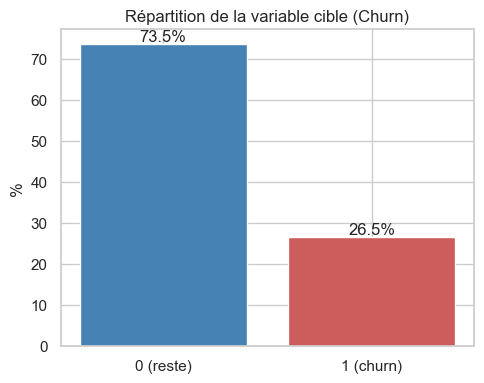

Taux de churn - entraînement : 0.265 | test : 0.265


In [5]:
effectifs = df[CIBLE].value_counts().sort_index()
repartition = pd.DataFrame({
    "effectif": effectifs,
    "pourcentage": (100 * effectifs / len(df)).round(2),
})
repartition.index = repartition.index.map({0: "0 (reste)", 1: "1 (churn)"})
display(repartition)

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(repartition.index, repartition["pourcentage"], color=["steelblue", "indianred"])
ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.set_ylabel("%")
ax.set_title("Répartition de la variable cible (Churn)")
plt.tight_layout()
plt.show()

print(f"Taux de churn - entraînement : {df_train[CIBLE].mean():.3f} | test : {df_test[CIBLE].mean():.3f}")

### 4.2 Variables numériques

Statistiques descriptives (avec l'asymétrie), puis histogramme et boîte à moustaches de chaque variable.

,count,mean,std,min,25%,50%,75%,max,asymetrie
tenure,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00,0.24
MonthlyCharges,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75,-0.22
TotalCharges,7043.0,2279.73,2266.79,0.00,398.55,1394.55,3786.60,8684.80,0.96


Clients avec tenure == 0 : 11


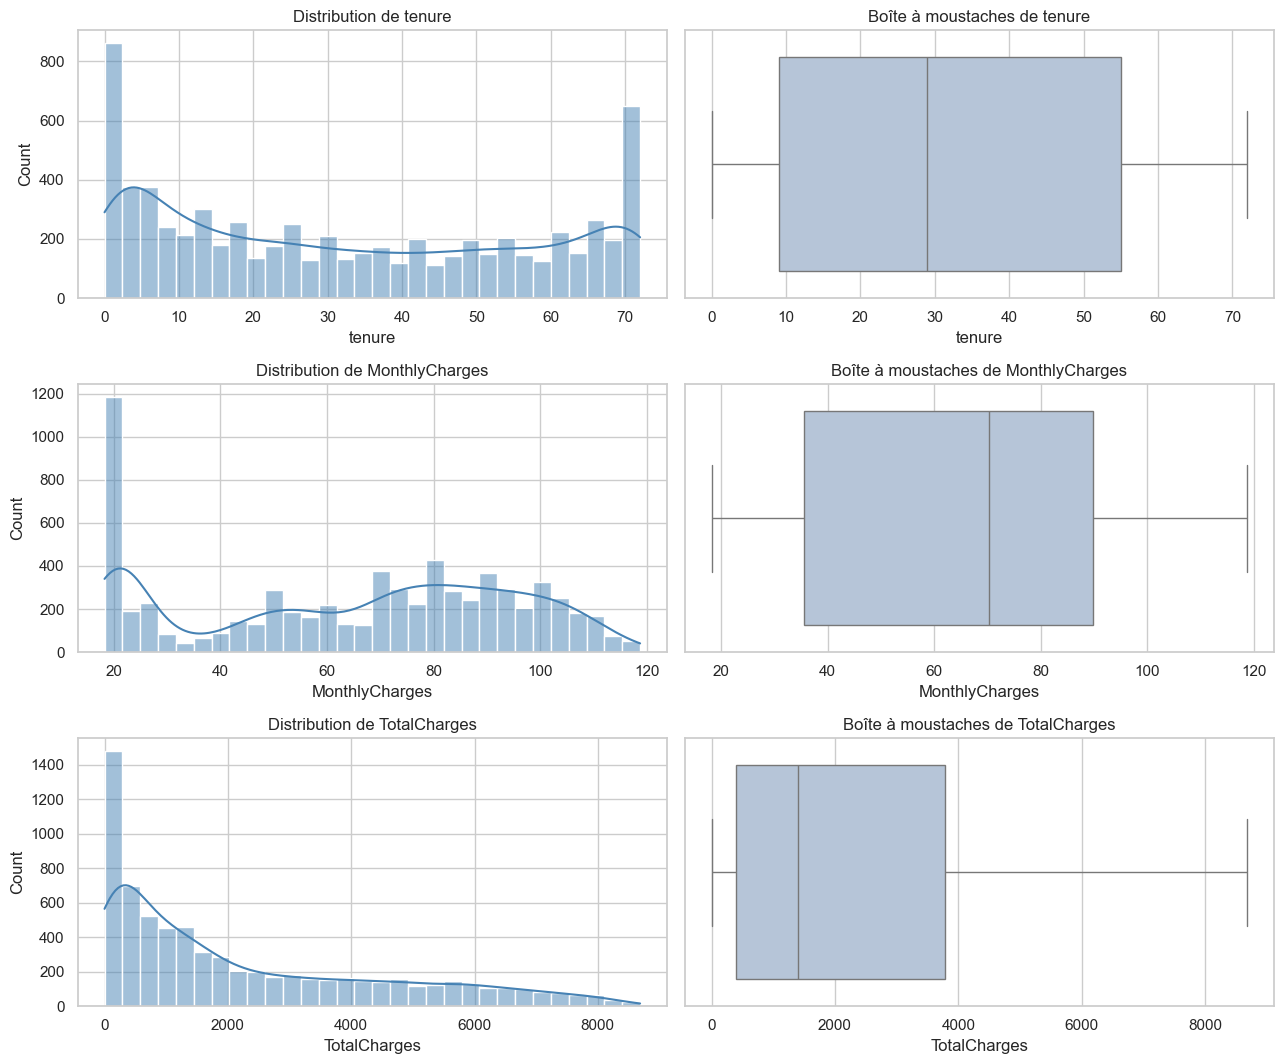

In [6]:
description = df[VARIABLES_NUMERIQUES].describe().T
description["asymetrie"] = df[VARIABLES_NUMERIQUES].skew()
display(description.round(2))

print(f"Clients avec tenure == 0 : {(df['tenure'] == 0).sum()}")

fig, axes = plt.subplots(
    len(VARIABLES_NUMERIQUES), 2, figsize=(13, 3.6 * len(VARIABLES_NUMERIQUES))
)
for i, col in enumerate(VARIABLES_NUMERIQUES):
    sns.histplot(df[col], bins=30, kde=True, ax=axes[i, 0], color="steelblue")
    axes[i, 0].set_title(f"Distribution de {col}")
    sns.boxplot(x=df[col], ax=axes[i, 1], color="lightsteelblue")
    axes[i, 1].set_title(f"Boîte à moustaches de {col}")
plt.tight_layout()
plt.show()

### 4.3 Variables catégorielles

Tableau de fréquences de **toutes** les modalités, puis un graphique de répartition par variable.

In [7]:
tables = []
for col in VARIABLES_CATEGORIELLES:
    comptes = df[col].astype(str).value_counts()
    tables.append(pd.DataFrame({
        "variable": col,
        "modalite": comptes.index,
        "effectif": comptes.values,
        "pourcentage": (100 * comptes.values / len(df)).round(2),
    }))
frequences = pd.concat(tables, ignore_index=True)

pd.set_option("display.max_rows", 100)
display(frequences)

,variable,modalite,effectif,pourcentage
0,gender,Male,3555,50.48
1,gender,Female,3488,49.52
2,SeniorCitizen,0,5901,83.79
3,SeniorCitizen,1,1142,16.21
4,Partner,No,3641,51.70
5,Partner,Yes,3402,48.30
6,Dependents,No,4933,70.04
7,Dependents,Yes,2110,29.96
8,PhoneService,Yes,6361,90.32
9,PhoneService,No,682,9.68


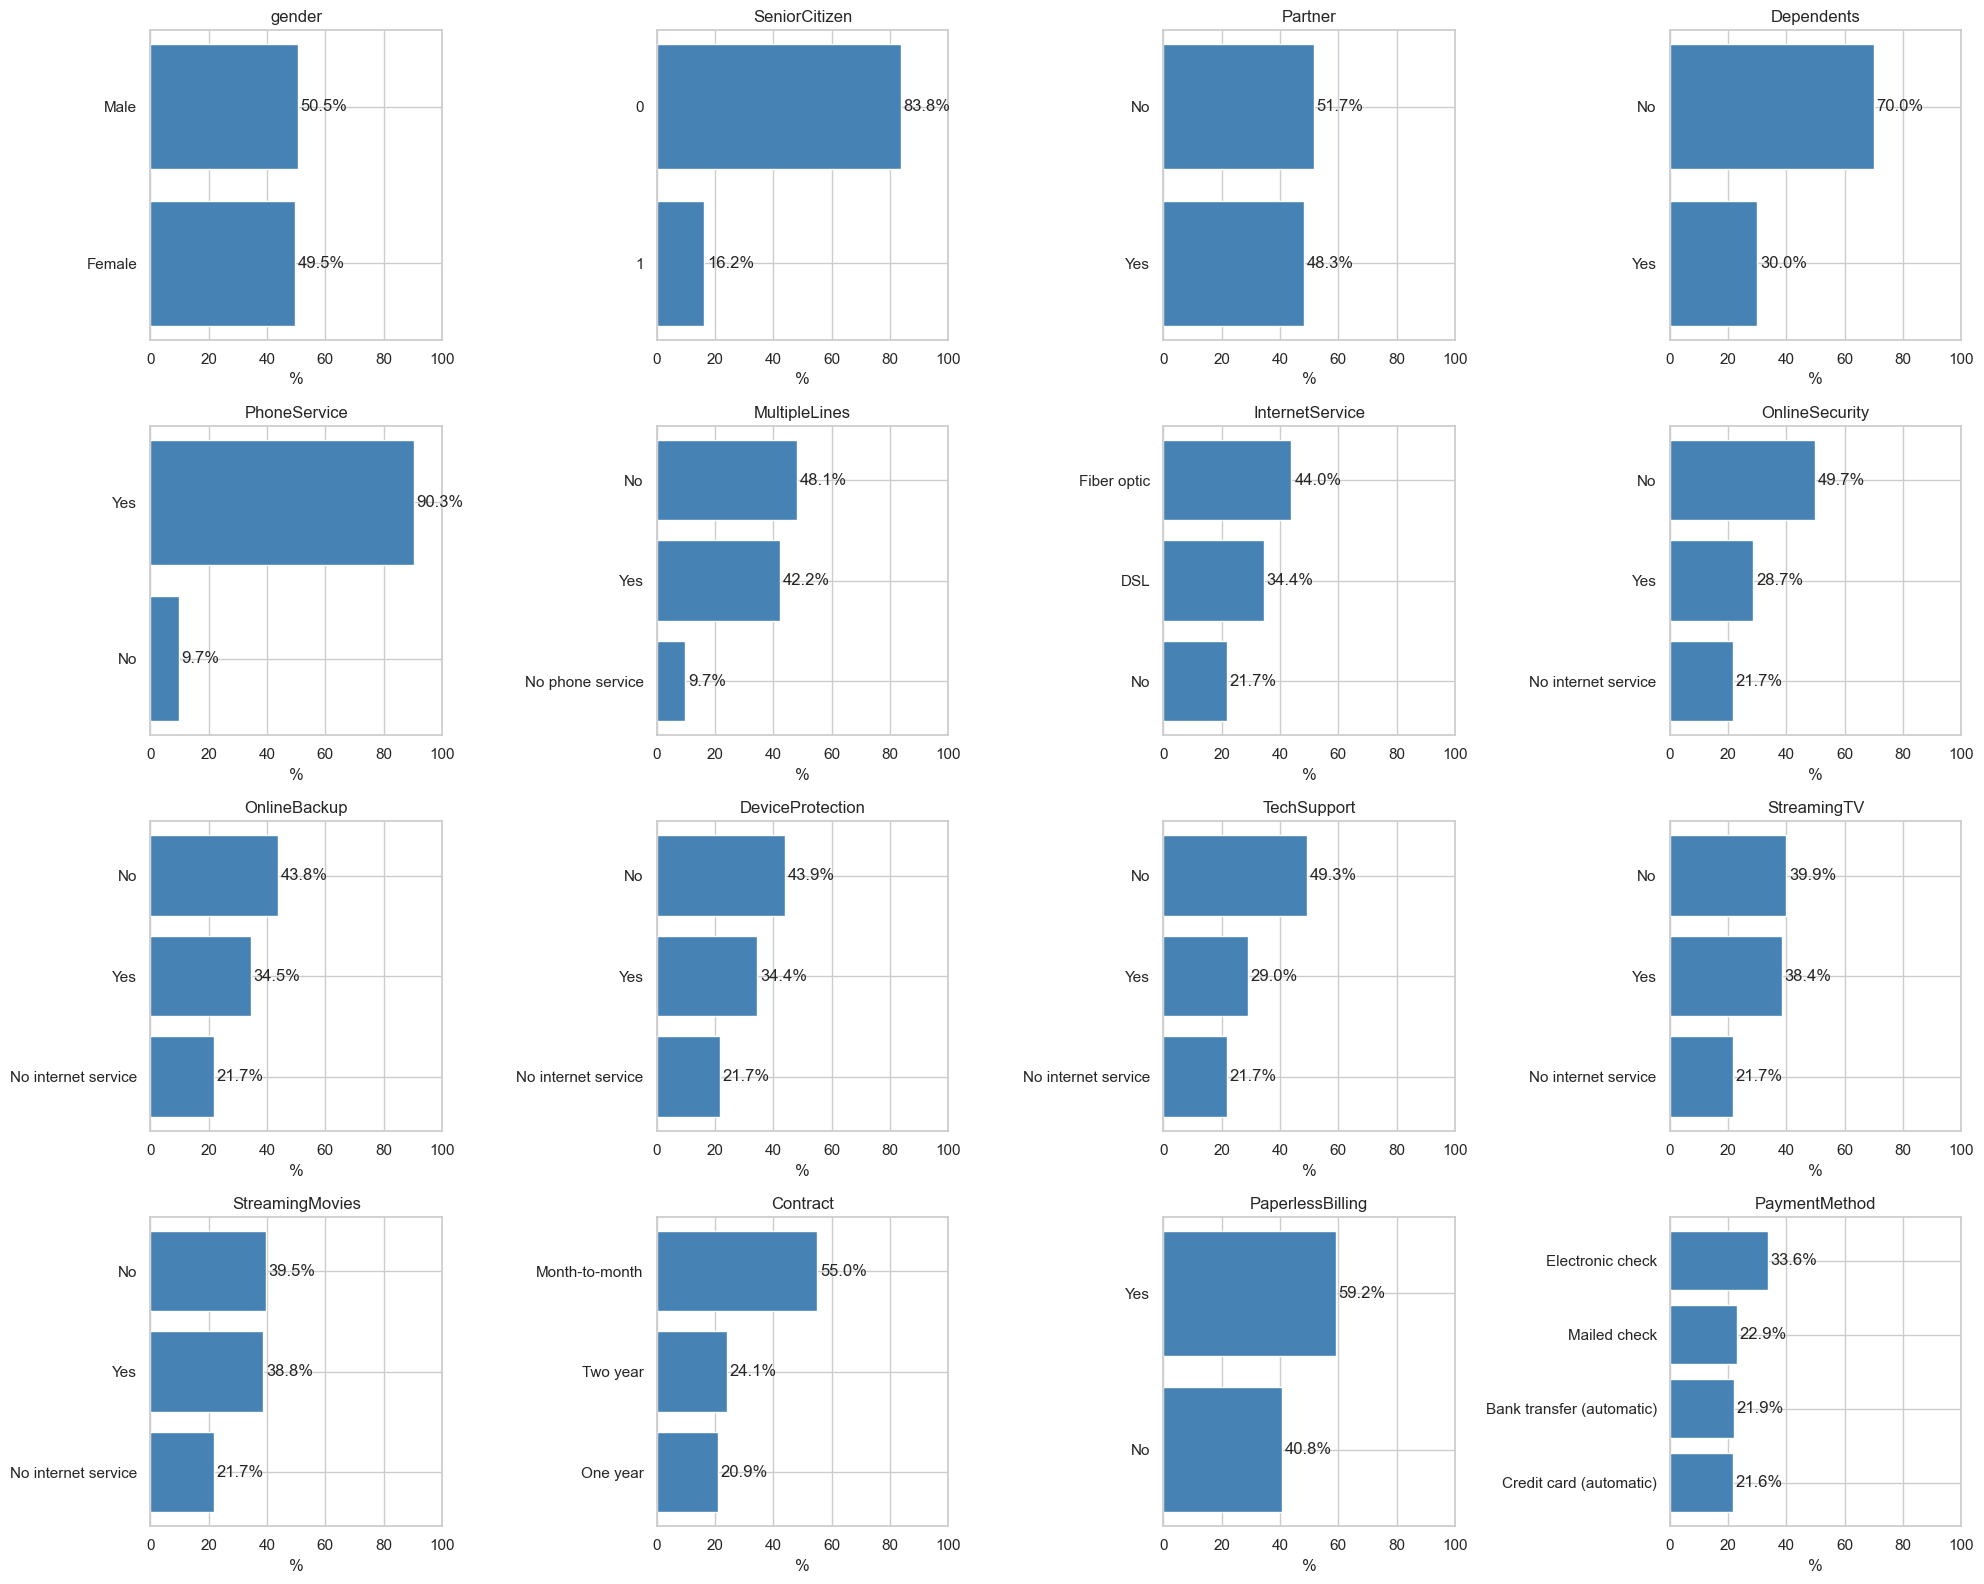

In [8]:
n_colonnes = 4
n_lignes = int(np.ceil(len(VARIABLES_CATEGORIELLES) / n_colonnes))

fig, axes = plt.subplots(n_lignes, n_colonnes, figsize=(20, 4 * n_lignes))
for ax, col in zip(axes.flat, VARIABLES_CATEGORIELLES):
    pct = df[col].astype(str).value_counts(normalize=True).mul(100).sort_values()
    ax.barh(pct.index, pct.values, color="steelblue")
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=2)
    ax.set_title(col)
    ax.set_xlim(0, 100)
    ax.set_xlabel("%")

# Masquer les cases vides de la grille
for ax in list(axes.flat)[len(VARIABLES_CATEGORIELLES):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

### 4.4 Modalités rares et variables quasi constantes

Une modalité très rare est difficile à exploiter par le modèle (on peut la regrouper avec une autre),
et une variable dont une seule modalité domine apporte très peu d'information.

In [9]:
SEUIL_RARE = 5         # % : en dessous, la modalité est rare
SEUIL_DOMINANTE = 90   # % : au-dessus, la variable est quasi constante

rares = frequences[frequences["pourcentage"] < SEUIL_RARE]
print(f"Modalités rares (< {SEUIL_RARE} %) :")
display(rares)

dominantes = (
    frequences.sort_values("pourcentage", ascending=False)
    .drop_duplicates("variable")
    .query("pourcentage >= @SEUIL_DOMINANTE")
)
print(f"Variables quasi constantes (modalité dominante >= {SEUIL_DOMINANTE} %) :")
display(dominantes)

Modalités rares (< 5 %) :


,variable,modalite,effectif,pourcentage


Variables quasi constantes (modalité dominante >= 90 %) :


,variable,modalite,effectif,pourcentage
8,PhoneService,Yes,6361,90.32


## 5. Variables numériques (relation avec Churn et entre elles)

### 5.1 Corrélations (Pearson et Spearman), cible incluse

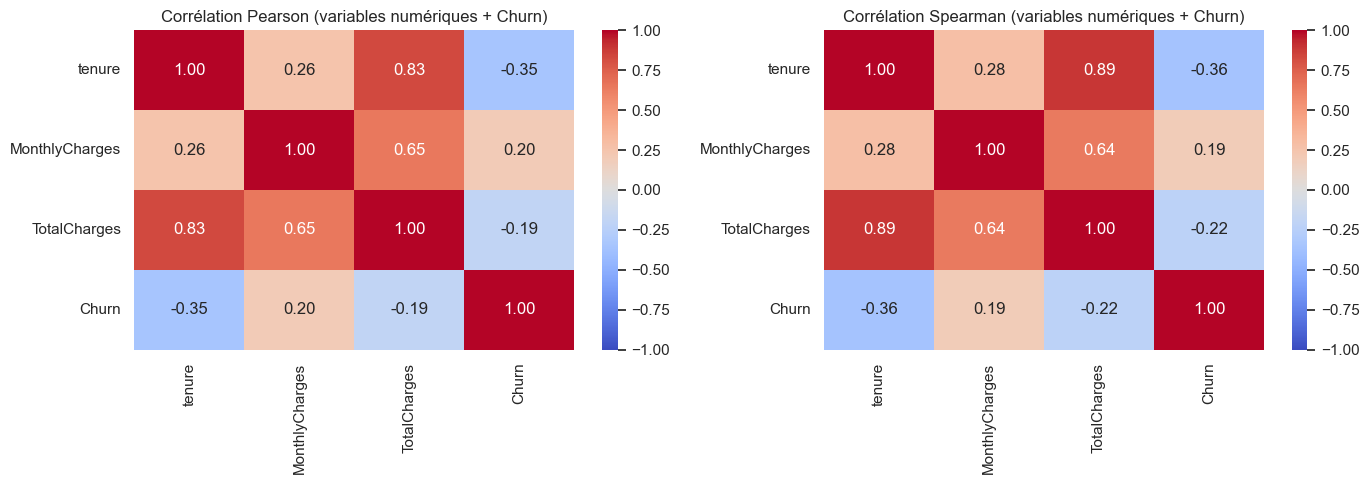

In [10]:
colonnes = VARIABLES_NUMERIQUES + [CIBLE]
corr_pearson = df_train[colonnes].corr(method="pearson")
corr_spearman = df_train[colonnes].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, corr, titre in zip(axes, [corr_pearson, corr_spearman], ["Pearson", "Spearman"]):
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
    ax.set_title(f"Corrélation {titre} (variables numériques + Churn)")
plt.tight_layout()
plt.show()

### 5.2 Vérification d'une redondance attendue

`TotalCharges` devrait être proche de `tenure × MonthlyCharges`.

In [11]:
approximation = df_train["tenure"] * df_train["MonthlyCharges"]
r = df_train["TotalCharges"].corr(approximation)
print(f"Corrélation entre TotalCharges et tenure × MonthlyCharges : {r:.3f}")

Corrélation entre TotalCharges et tenure × MonthlyCharges : 1.000


## 6. Variables catégorielles (relation avec Churn et entre elles)

### 6.1 V de Cramér : fonction utilitaire

On utilise la version **corrigée du biais** (Bergsma), plus fiable quand certaines
modalités sont rares.

In [12]:
def cramers_v(x, y, correction=True):
    """V de Cramér entre deux variables catégorielles (entre 0 et 1)."""
    table = pd.crosstab(x, y)
    if min(table.shape) < 2:
        return 0.0
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.values.sum()
    r, k = table.shape
    phi2 = chi2 / n
    if correction:
        phi2 = max(0.0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
        r = r - ((r - 1) ** 2) / (n - 1)
        k = k - ((k - 1) ** 2) / (n - 1)
    denominateur = min(k - 1, r - 1)
    return float(np.sqrt(phi2 / denominateur)) if denominateur > 0 else 0.0

### 6.2 Variables catégorielles vs `Churn`

,variable,n_modalites,cramers_v,p_value
0,Contract,3,0.4107,0.0000
1,OnlineSecurity,3,0.3506,0.0000
2,TechSupport,3,0.3444,0.0000
3,InternetService,3,0.3261,0.0000
4,PaymentMethod,4,0.3103,0.0000
5,OnlineBackup,3,0.2937,0.0000
6,DeviceProtection,3,0.2793,0.0000
7,StreamingMovies,3,0.2309,0.0000
8,StreamingTV,3,0.2296,0.0000
9,PaperlessBilling,2,0.1975,0.0000


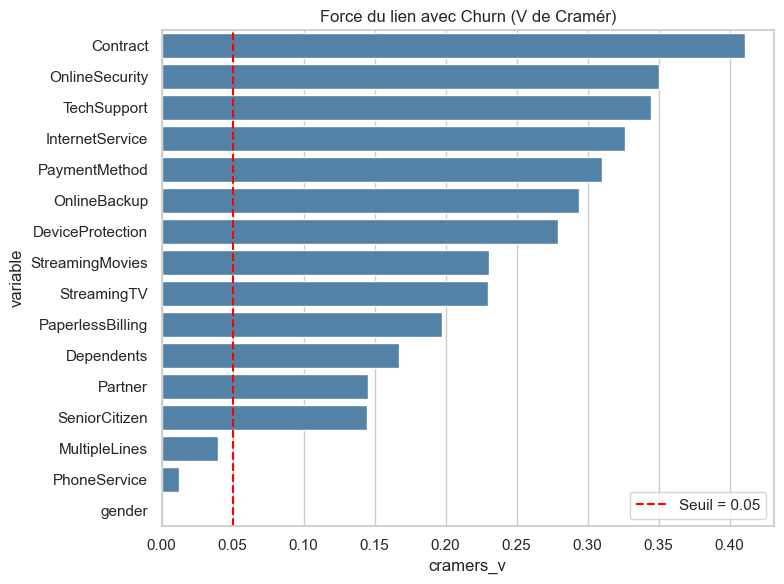

In [13]:
resultats = []
for col in VARIABLES_CATEGORIELLES:
    table = pd.crosstab(df_train[col], df_train[CIBLE])
    _, p_value, _, _ = chi2_contingency(table)
    resultats.append({
        "variable": col,
        "n_modalites": table.shape[0],
        "cramers_v": cramers_v(df_train[col], df_train[CIBLE]),
        "p_value": p_value,
    })

assoc_cat = (
    pd.DataFrame(resultats)
    .sort_values("cramers_v", ascending=False)
    .reset_index(drop=True)
)
display(assoc_cat.round(4))

plt.figure(figsize=(8, 6))
sns.barplot(data=assoc_cat, x="cramers_v", y="variable", color="steelblue")
plt.axvline(SEUIL_PERTINENCE, color="red", linestyle="--", label=f"Seuil = {SEUIL_PERTINENCE}")
plt.title("Force du lien avec Churn (V de Cramér)")
plt.legend()
plt.tight_layout()
plt.show()

### 6.3 Redondance entre variables catégorielles

Matrice de V de Cramér entre **toutes** les paires de variables catégorielles.

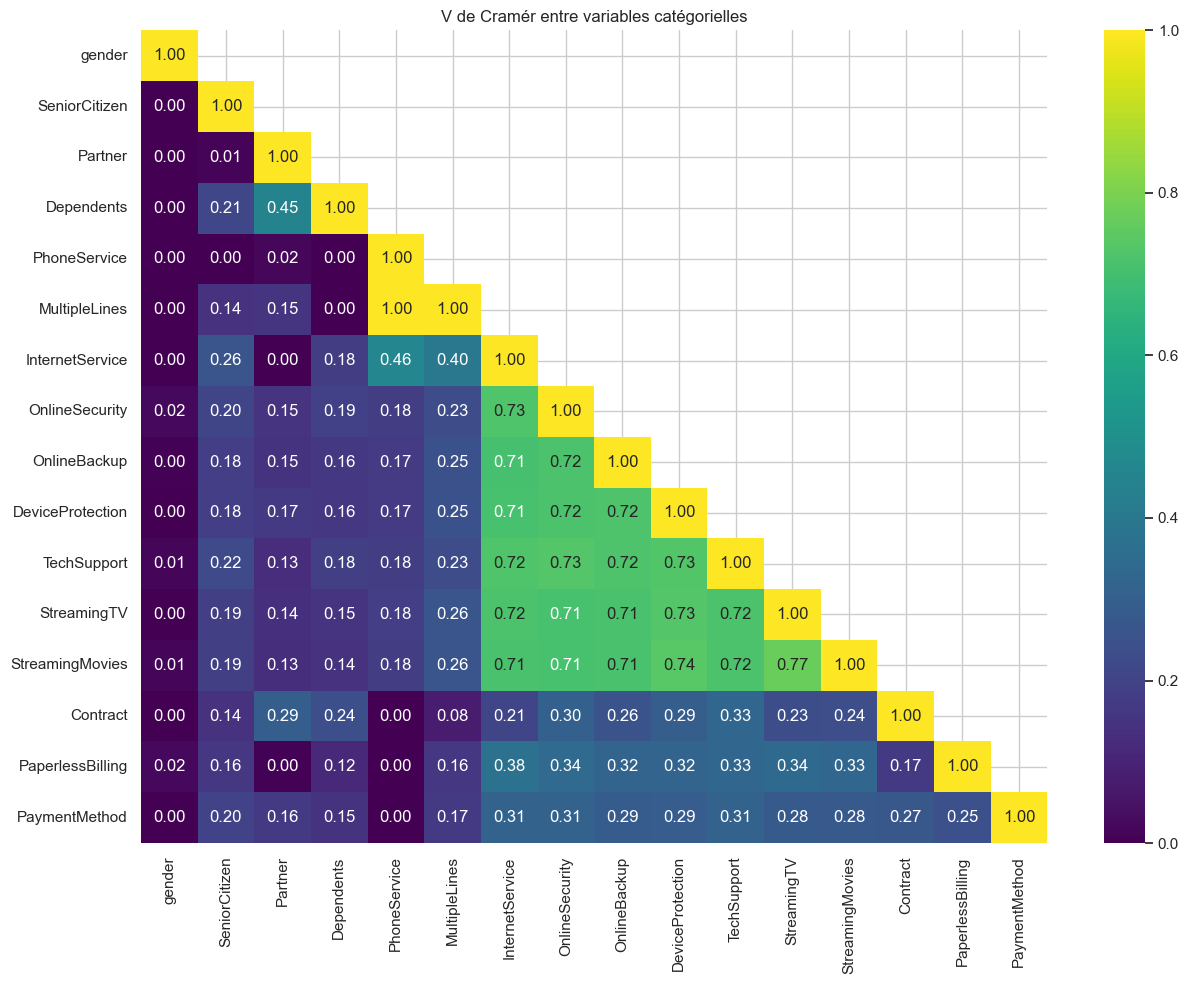

In [14]:
cols = VARIABLES_CATEGORIELLES
matrice_v = pd.DataFrame(np.eye(len(cols)), index=cols, columns=cols)
for i, a in enumerate(cols):
    for b in cols[i + 1:]:
        v = cramers_v(df_train[a], df_train[b])
        matrice_v.loc[a, b] = v
        matrice_v.loc[b, a] = v

masque = np.triu(np.ones_like(matrice_v, dtype=bool), k=1)
plt.figure(figsize=(13, 10))
sns.heatmap(matrice_v, mask=masque, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1)
plt.title("V de Cramér entre variables catégorielles")
plt.tight_layout()
plt.show()

In [15]:
paires = [
    {"variable_a": a, "variable_b": b, "cramers_v": matrice_v.loc[a, b]}
    for i, a in enumerate(cols) for b in cols[i + 1:]
]
paires = pd.DataFrame(paires).sort_values("cramers_v", ascending=False).reset_index(drop=True)

print("15 paires les plus redondantes :")
display(paires.head(15).round(3))

15 paires les plus redondantes :


,variable_a,variable_b,cramers_v
0,PhoneService,MultipleLines,1.000
1,StreamingTV,StreamingMovies,0.772
2,DeviceProtection,StreamingMovies,0.739
3,DeviceProtection,StreamingTV,0.734
4,OnlineSecurity,TechSupport,0.733
5,DeviceProtection,TechSupport,0.728
6,InternetService,OnlineSecurity,0.725
7,InternetService,TechSupport,0.723
8,OnlineBackup,TechSupport,0.720
9,OnlineBackup,DeviceProtection,0.719


> **À noter.** Les colonnes `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`,
> `StreamingTV` et `StreamingMovies` contiennent la modalité « No internet service », qui est
> exactement équivalente à `InternetService == "No"`. De même, « No phone service » dans
> `MultipleLines` équivaut à `PhoneService == "No"`. Cette redondance est **structurelle** :
> plutôt que de supprimer ces variables, on peut recoder ces modalités en « No » (l'information
> reste dans `InternetService` / `PhoneService`).

## 7. Information mutuelle avec `Churn` (toutes les variables)

L'information mutuelle fonctionne pour les variables numériques **et** catégorielles et capte
aussi les relations non linéaires. C'est la seule mesure ici directement comparable entre
toutes les variables.

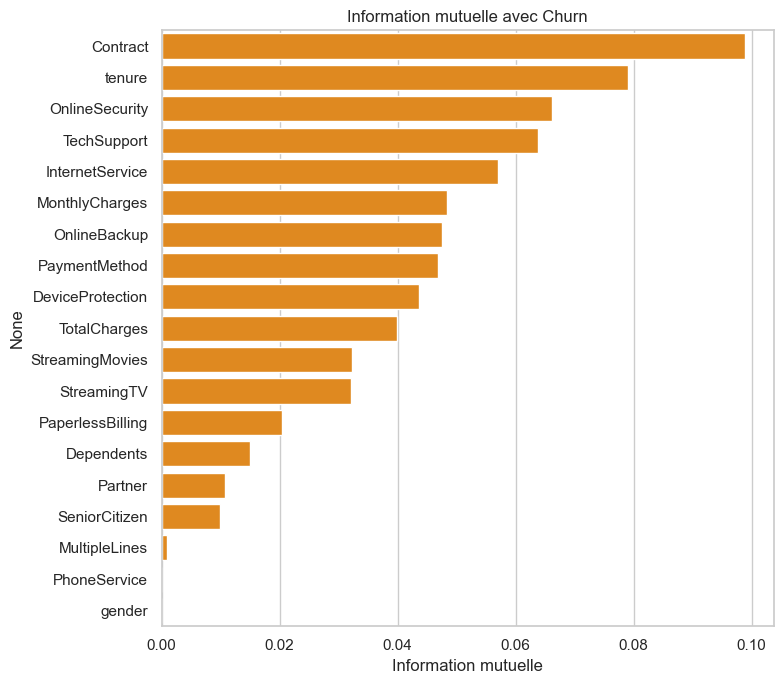

In [16]:
X = df_train[VARIABLES_NUMERIQUES + VARIABLES_CATEGORIELLES].copy()
X[VARIABLES_CATEGORIELLES] = OrdinalEncoder().fit_transform(
    X[VARIABLES_CATEGORIELLES].astype(str)
)
masque_discret = [c in VARIABLES_CATEGORIELLES for c in X.columns]

mi = mutual_info_classif(
    X, df_train[CIBLE], discrete_features=masque_discret, random_state=RANDOM_STATE
)
info_mutuelle = pd.Series(mi, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 7))
sns.barplot(x=info_mutuelle.values, y=info_mutuelle.index, color="darkorange")
plt.title("Information mutuelle avec Churn")
plt.xlabel("Information mutuelle")
plt.tight_layout()
plt.show()

## 8. Synthèse : candidates à la suppression

Pour chaque variable on regroupe :

- `association_churn` : |corrélation| (numériques) ou V de Cramér (catégorielles) avec `Churn` ;
- `info_mutuelle` : information mutuelle avec `Churn` ;
- `partenaire` / `redondance` : la variable avec laquelle elle est le plus liée, et la force de ce lien.

Règles de signalement (les seuils se règlent en haut du notebook) :

- **faible lien** si `association_churn < SEUIL_PERTINENCE` ;
- **redondante** si `redondance >= SEUIL_REDONDANCE` **et** que son lien avec `Churn` est plus faible
  que celui de son partenaire.

In [17]:
lignes = []

for col in VARIABLES_NUMERIQUES:
    autres = [c for c in VARIABLES_NUMERIQUES if c != col]
    lien = corr_pearson.loc[col, autres].abs()
    lignes.append({
        "variable": col,
        "type": "numérique",
        "association_churn": abs(corr_pearson.loc[col, CIBLE]),
        "info_mutuelle": info_mutuelle[col],
        "partenaire": lien.idxmax(),
        "redondance": lien.max(),
    })

v_cible = assoc_cat.set_index("variable")["cramers_v"]
for col in VARIABLES_CATEGORIELLES:
    autres = [c for c in VARIABLES_CATEGORIELLES if c != col]
    lien = matrice_v.loc[col, autres]
    lignes.append({
        "variable": col,
        "type": "catégorielle",
        "association_churn": v_cible[col],
        "info_mutuelle": info_mutuelle[col],
        "partenaire": lien.idxmax(),
        "redondance": lien.max(),
    })

resume = pd.DataFrame(lignes).set_index("variable")


def signaler(ligne):
    partenaire = ligne["partenaire"]
    if ligne["association_churn"] < SEUIL_PERTINENCE:
        return "à examiner : faible lien avec Churn"
    if (
        ligne["redondance"] >= SEUIL_REDONDANCE
        and ligne["association_churn"] < resume.loc[partenaire, "association_churn"]
    ):
        return f"à examiner : redondante avec {partenaire}"
    return "conserver"


resume["decision"] = resume.apply(signaler, axis=1)
resume = resume.sort_values("info_mutuelle", ascending=False)
display(resume.round(3))

candidates = resume[resume["decision"] != "conserver"]
print(f"\n{len(candidates)} variable(s) à examiner sur {len(resume)} :")
print(candidates["decision"].to_string())

,type,association_churn,info_mutuelle,partenaire,redondance,decision
variable,,,,,,
Contract,catégorielle,0.411,0.099,TechSupport,0.331,conserver
tenure,numérique,0.346,0.079,TotalCharges,0.830,conserver
OnlineSecurity,catégorielle,0.351,0.066,TechSupport,0.733,conserver
TechSupport,catégorielle,0.344,0.064,OnlineSecurity,0.733,conserver
InternetService,catégorielle,0.326,0.057,OnlineSecurity,0.725,conserver
MonthlyCharges,numérique,0.198,0.048,TotalCharges,0.654,conserver
OnlineBackup,catégorielle,0.294,0.047,TechSupport,0.720,conserver
PaymentMethod,catégorielle,0.310,0.047,InternetService,0.313,conserver
DeviceProtection,catégorielle,0.279,0.044,StreamingMovies,0.739,conserver



4 variable(s) à examiner sur 19 :
variable
TotalCharges     à examiner : redondante avec tenure
MultipleLines    à examiner : faible lien avec Churn
PhoneService     à examiner : faible lien avec Churn
gender           à examiner : faible lien avec Churn


## 9. Conclusions et prochaines étapes

Ces résultats sont des **candidates**, pas des décisions définitives :

1. Un faible lien avec `Churn` n'implique pas qu'une variable soit inutile (interactions possibles).
2. Pour valider, entraîner le modèle de référence (régression logistique) **avec toutes les variables**
   puis **sans les candidates**, et comparer les métriques sur le jeu de test
   (AUC, rappel, précision).
3. Si les performances sont équivalentes, on conserve la version réduite (modèle plus simple,
   API plus légère). Sinon, on garde les variables concernées.
4. Les liens numérique ↔ catégorielle (par exemple `MonthlyCharges` selon les services souscrits)
   ne sont pas couverts ici ; ils peuvent faire l'objet d'une analyse complémentaire (rapport de corrélation η²).